# Explore Wikispeedia Paths and Graph Data

In [1]:
import numpy as np
import pandas as pd
import os
from urllib.parse import unquote
import random
from time import sleep
import pickle
import json
import copy
import re
import regex
import matplotlib.pyplot as plt
import sys
sys.path.append('../')
from utils import effective_path, get_paths_real_sample


%load_ext autoreload
%autoreload 2

random.seed(42)
pd.set_option('display.max_colwidth', None)

PATH_IN = '../../data/wikispeedia/wikispeedia_paths-and-graph/'
PATH_EMB = '../../data/wikispeedia/embeddings/'

In [2]:
# View embedding pickles at PATH_EMB
deepwalk_path = PATH_EMB + 'deepwalk_wikispeedia_undirected.pickle'
openai_path = PATH_EMB + 'openai_wikispeedia.pickle'

# open pickle files
with open(deepwalk_path, 'rb') as f:
    deepwalk = pickle.load(f)

with open(openai_path, 'rb') as f:
    openai = pickle.load(f)

target = 'Portugal'
links = ['France', 'São_Tomé_and_Príncipe', 'Animal', 'Winston_Churchill']

# compute cosine similarity
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# compute cosine similarity between target and links
link_similarities = {}
for link in links:
    link_similarities[link] = cosine_similarity(openai[target], openai[link])

# sort links by similarity
sorted_links = sorted(link_similarities.items(), key=lambda x: x[1], reverse=True)
sorted_links

[('São_Tomé_and_Príncipe', 0.8480734657085068),
 ('France', 0.8458171098083571),
 ('Winston_Churchill', 0.7255774716125166),
 ('Animal', 0.7154927164419413)]

# Explore paths_real_processed_df

In [10]:
paths_real_processed_df = pd.read_csv(os.path.join(PATH_IN, 'paths_real_processed.tsv'), sep='\t')
paths_real_processed_df.query('is_path_finished==1').query('src=="Achilles" and tgt=="Winston_Churchill"')

/tmp/ipykernel_2298803/3095761751.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  paths_real_processed_df = pd.read_csv(os.path.join(PATH_IN, 'paths_real_processed.tsv'), sep='\t')


,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl,shepl,mhepl
103,4fa1042c62308f16,1230177578,Achilles,Winston_Churchill,1,NaN,Achilles;Trojan_War;Italy;Great_Britain;England;Winston_Churchill,5,2,224,85,2.0,Achilles;Trojan_War;Italy;Great_Britain;England;Winston_Churchill,5,2.0,2.0,3.5
104,74f486b2625fadb5,1233236054,Achilles,Winston_Churchill,1,NaN,Achilles;William_Shakespeare;British_Empire;World_War_II;Winston_Churchill,4,2,88,85,NaN,Achilles;William_Shakespeare;British_Empire;World_War_II;Winston_Churchill,4,2.0,2.0,3.5
105,321e4b101c5b58ff,1233269042,Achilles,Winston_Churchill,1,NaN,Achilles;World_War_II;Winston_Churchill,2,2,46,85,1.0,Achilles;World_War_II;Winston_Churchill,2,2.0,2.0,3.5
106,4dc8af51482ebb5a,1336876538,Achilles,Winston_Churchill,1,NaN,Achilles;Ethiopia;United_Kingdom;World_War_II;Winston_Churchill,4,2,221,85,3.0,Achilles;Ethiopia;United_Kingdom;World_War_II;Winston_Churchill,4,2.0,2.0,3.5
107,7a9183f72e699f33,1342494087,Achilles,Winston_Churchill,1,NaN,Achilles;World_War_II;Winston_Churchill,2,2,51,85,1.0,Achilles;World_War_II;Winston_Churchill,2,2.0,2.0,3.5
108,0adc390d00c8c538,1344743190,Achilles,Winston_Churchill,1,NaN,Achilles;Greek_mythology;Ancient_Greece;Europe;United_Kingdom;Prime_Minister_of_the_United_Kingdom;Winston_Churchill,6,2,63,85,3.0,Achilles;Greek_mythology;Ancient_Greece;Europe;United_Kingdom;Prime_Minister_of_the_United_Kingdom;Winston_Churchill,6,2.0,2.0,3.5
109,44cbc4b202f60da1,1345393295,Achilles,Winston_Churchill,1,NaN,Achilles;Ukraine;World_War_II;Winston_Churchill,3,2,72,85,NaN,Achilles;Ukraine;World_War_II;Winston_Churchill,3,2.0,2.0,3.5
110,31980f901eee5467,1346717015,Achilles,Winston_Churchill,1,NaN,Achilles;Ethiopia;United_Kingdom;World_War_II;Winston_Churchill,4,2,117,85,NaN,Achilles;Ethiopia;United_Kingdom;World_War_II;Winston_Churchill,4,2.0,2.0,3.5
111,7d5624e35c9523ef,1350409465,Achilles,Winston_Churchill,1,NaN,Achilles;Black_Sea;<;Romania;World_War_II;Winston_Churchill,5,2,81,85,NaN,Achilles;Romania;World_War_II;Winston_Churchill,3,2.0,2.0,3.5
112,7d5624e35c9523ef,1350409530,Achilles,Winston_Churchill,1,NaN,Achilles;William_Shakespeare;England;<;<;World_War_II;Winston_Churchill,6,2,157,85,NaN,Achilles;World_War_II;Winston_Churchill,2,2.0,2.0,3.5


spl
3    63
2    18
4    17
5     2
Name: count, dtype: int64


<Axes: >

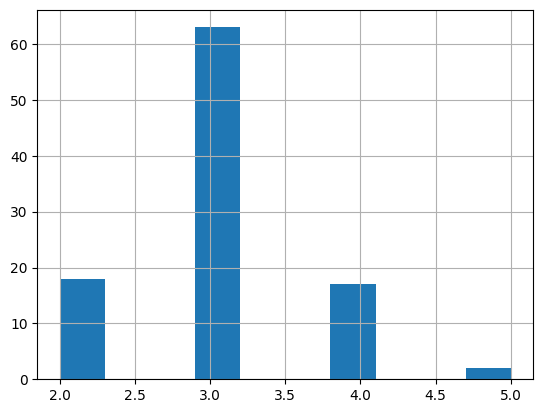

In [9]:
print(paths_real_processed_df.groupby(['src', 'tgt']).agg({"spl":"min","shpl": "min", "shepl": "min"}).reset_index().sample(n=100, random_state=42)['spl'].value_counts())
paths_real_processed_df.groupby(['src', 'tgt']).agg({"spl":"min","shpl": "min", "shepl": "min"}).reset_index().sample(n=100, random_state=42)['spl'].hist()

spl
3    524
2    222
4    217
5     33
6      4
Name: count, dtype: int64


<Axes: >

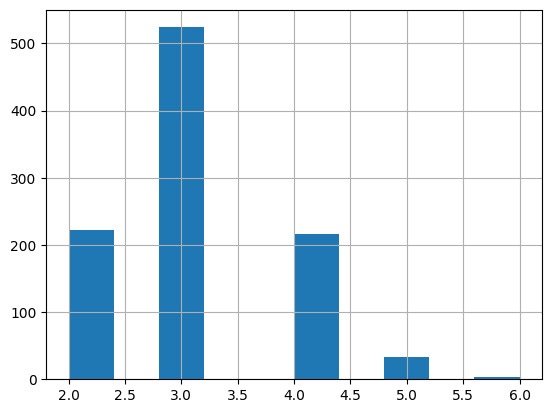

In [8]:
print(paths_real_processed_df.groupby(['src', 'tgt']).agg({"spl":"min","shpl": "min", "shepl": "min"}).reset_index().sample(n=1000, random_state=42)['spl'].value_counts())
paths_real_processed_df.groupby(['src', 'tgt']).agg({"spl":"min","shpl": "min", "shepl": "min"}).reset_index().sample(n=1000, random_state=42)['spl'].hist()

## Build paths_real_processed_df
`paths_real_df` (from Akhil) has the columns:
 - hashed_ip: user identifier
 - timestamp: time of the game
 - src, tgt: source and target pages
 - is_path_finished: whether the user reached the target page
 - failure_type: reason for failure (restart, timout, ...)
 - path: path taken (including backtracks)
 - hpl: Human Path Length (number of clicks by human, including backtracks)
 - spl: Shortest Path Length (shortest possible path length for that pair)
 - duration_in_sec: time taken by user
 - target_in_degree: number of incoming links to target page
 - user_path_rating: 1-5 rating of path difficulty by user

We're gonna add:
 - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
 - effective_path: path taken by user excluding backtracks
 - hepl: Human Effective Path Length (effective path length for that game instance)
 - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

We remove the paths from the fewshot demonstrations, and paths with SPL==1, meaning the target page is a link on the source page.

The final df is `paths_real_processed_df`

In [2]:
# `paths_real_df` (from Akhil) has the columns:
#  - hashed_ip: user identifier
#  - timestamp: time of the game
#  - src, tgt: source and target pages
#  - is_path_finished: whether the user reached the target page
#  - failure_type: reason for failure (restart, timout, ...)
#  - path: path taken (including backtracks)
#  - hpl: Human Path Length (number of clicks by human, including backtracks)
#  - spl: Shortest Path Length (shortest possible path length for that pair)
#  - duration_in_sec: time taken by user
#  - target_in_degree: number of incoming links to target page
#  - user_path_rating: 1-5 rating of path difficulty by user

# We're gonna add:
#  - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
#  - effective_path: path taken by user excluding backtracks
#  - hepl: Human Effective Path Length (effective path length for that game instance)
#  - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)
#  - mhepl: Median Human Effective Path Length (median effective path length made by human, for that pair)
# The final df is `paths_real_processed_df`

paths_real_processed_df = pd.read_csv(PATH_IN + 'paths_real_df.csv')


paths_real_processed_df["effective_path"] = paths_real_processed_df.apply(lambda row: effective_path(row["path"]), axis=1)
paths_real_processed_df["hepl"] = paths_real_processed_df.apply(lambda row: len(row["effective_path"].split(";"))-1, axis=1)

# add a column that is the shortest human path length for that pair, by choosing the minimum path_length for all games with that pair
shpl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hpl": "min"}).reset_index().rename(columns={"hpl": "shpl"})
shepl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"hepl": "shepl"})
mhepl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "median"}).reset_index().rename(columns={"hepl": "mhepl"})


paths_real_processed_df = pd.merge(paths_real_processed_df, shpl, on=['src', 'tgt'], how='left')
paths_real_processed_df = pd.merge(paths_real_processed_df, shepl, on=['src', 'tgt'], how='left')
paths_real_processed_df = pd.merge(paths_real_processed_df, mhepl, on=['src', 'tgt'], how='left')

# keep only paths that are longer than 1 click
paths_real_processed_df = paths_real_processed_df.query("spl > 1")


In [16]:
# remove fewshot demonstrations from paths_real_processed_df

FEWSHOT_DEMOS_FILE = os.path.join(PATH_IN, 'fewshot_click_demonstrations.tsv')

fewshot_df = pd.read_csv(FEWSHOT_DEMOS_FILE, sep='\t')
fewshot_df = fewshot_df[['src', 'tgt']].drop_duplicates()

paths_real_processed_df = paths_real_processed_df[~paths_real_processed_df[['src', 'tgt']].apply(tuple,1).isin(fewshot_df[['src', 'tgt']].apply(tuple,1))]

paths_real_processed_df.query("src=='Gas' and tgt=='Organism'")

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl,shepl,mhepl


In [5]:
paths_real_processed_df.to_csv(PATH_IN + 'paths_real_processed.tsv', sep='\t', index=False)

In [18]:
# see spl distribution of games finished at least 4 different times (the count of is_path_finished for a src,tgt pair is the number of times the game was finished)
len(paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"is_path_finished": "count", "spl": "min"}).query("is_path_finished >= 4"))


1914

In [14]:
paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"is_path_finished": "count", "spl": "min"}).query("is_path_finished >= 3")["spl"].sample(200).value_counts()


spl
3    121
2     46
4     32
5      1
Name: count, dtype: int64

In [19]:
paths_real_processed_df = pd.read_csv(PATH_IN + 'paths_real_df.csv')
paths_real_processed_df

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating
0,6a3701d319fc3754,1297740409,14th_century,African_slave_trade,1,NaN,14th_century;15th_century;16th_century;Pacific_Ocean;Atlantic_Ocean;Accra;Africa;Atlantic_slave_trade;African_slave_trade,8,3,166,7,NaN
1,3824310e536af032,1344753412,14th_century,African_slave_trade,1,NaN,14th_century;Europe;Africa;Atlantic_slave_trade;African_slave_trade,4,3,88,7,3.0
2,415612e93584d30e,1349298640,14th_century,African_slave_trade,1,NaN,14th_century;Niger;Nigeria;British_Empire;Slavery;Africa;Atlantic_slave_trade;African_slave_trade,7,3,138,7,NaN
3,64dd5cd342e3780c,1265613925,14th_century,Greece,1,NaN,14th_century;Renaissance;Ancient_Greece;Greece,3,2,37,246,NaN
4,015245d773376aab,1366730828,14th_century,John_F._Kennedy,1,NaN,14th_century;Italy;Roman_Catholic_Church;HIV;Ronald_Reagan;President_of_the_United_States;John_F._Kennedy,6,3,175,60,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...
76188,109ed71f571d86e9,1389787605,Franz_Kafka,Cholera,0,restart,Franz_Kafka;Tuberculosis;World_Health_Organization;Malaria;Philippines;<;Sub-Saharan_Africa;Ghana,7,3,180,38,NaN
76189,232f992e57d43e8d,1389787697,Modern_history,Hollandic,0,restart,Modern_history,0,3,6,8,NaN
76190,2e09a7224600a7cd,1389798400,Computer_programming,The_Beatles,0,timeout,Computer_programming;Linguistics;Culture;Popular_culture;<,4,3,1900,61,NaN
76191,60af9e2138051b96,1389799481,Jamaica,Alan_Turing,0,timeout,Jamaica;United_Kingdom;World_War_II;Battle_of_Midway,3,3,1903,11,NaN


In [4]:
paths_real_processed_df.query('hepl == spl and is_path_finished==1')

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl,shepl
6,36dabfa133b20e3c,1249525912,14th_century,Fire,1,NaN,14th_century;China;Gunpowder;Fire,3,3,112,37,2.0,14th_century;China;Gunpowder;Fire,3,3.0,3.0
8,08888b1b428dd90e,1232241510,14th_century,Rainbow,1,NaN,14th_century;Time;Light;Rainbow,3,3,74,11,3.0,14th_century;Time;Light;Rainbow,3,3.0,3.0
22,1c6947833f8d7a1e,1345522466,14th_century,Rainbow,1,NaN,14th_century;Time;Light;Rainbow,3,3,75,11,1.0,14th_century;Time;Light;Rainbow,3,3.0,3.0
23,1c6947833f8d7a1e,1345524107,14th_century,Rainbow,1,NaN,14th_century;Time;Light;Rainbow,3,3,25,11,NaN,14th_century;Time;Light;Rainbow,3,3.0,3.0
26,3e910d512cba8045,1346940696,14th_century,Rainbow,1,NaN,14th_century;Time;Isaac_Newton;Rainbow,3,3,76,11,NaN,14th_century;Time;Isaac_Newton;Rainbow,3,3.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51298,042970d020c2c8de,1382695495,Uluru,London_Bridge,1,NaN,Uluru;Australia;Continent;<;England;London;London_Bridge,6,4,39,9,NaN,Uluru;Australia;England;London;London_Bridge,4,6.0,4.0
51307,69d6678337665564,1308834694,"William_Thomson,_1st_Baron_Kelvin",Mercury_(planet),1,NaN,"William_Thomson,_1st_Baron_Kelvin;Astronomy;Mercury_(planet)",2,2,37,39,NaN,"William_Thomson,_1st_Baron_Kelvin;Astronomy;Mercury_(planet)",2,2.0,2.0
51312,052ba30a41ff5a05,1371787558,Work_(thermodynamics),Pyongyang,1,NaN,Work_(thermodynamics);Cambridge;City_status_in_the_United_Kingdom;<;1st_century_BC;Korea;Pyongyang,6,4,133,7,3.0,Work_(thermodynamics);Cambridge;1st_century_BC;Korea;Pyongyang,4,6.0,4.0
51313,15a13a1d66ef5456,1349231015,Yagan,Civilization,1,NaN,Yagan;Ancient_Egypt;Civilization,2,2,66,58,NaN,Yagan;Ancient_Egypt;Civilization,2,2.0,2.0


In [51]:
# paths_real_processed_df[(paths_real_processed_df["src"] == "14th_century") & (paths_real_processed_df["tgt"] == "Henry_David_Thoreau")]
# paths_real_processed_df[(paths_real_processed_df["shpl"].notna()) & (paths_real_processed_df["shepl"].notna()) & (paths_real_processed_df["shpl"] != paths_real_processed_df["shepl"])]
# show only unique src,tgt pairs
paths_real_processed_df.groupby(["src", "tgt"]).agg({"shpl": "min", "shepl": "min"}).reset_index()


,src,tgt,shpl,shepl
0,10th_century,11th_century,1.0,1.0
1,10th_century,Banknote,4.0,4.0
2,10th_century,Country,2.0,2.0
3,10th_century,Harlem_Globetrotters,3.0,3.0
4,10th_century,History_of_democracy,9.0,5.0
...,...,...,...,...
42625,Zürich,Mediterranean_Sea,3.0,3.0
42626,Zürich,Polar_ice_cap,NaN,NaN
42627,Zürich,Vegetation,NaN,NaN
42628,Zürich,Water_polo,NaN,NaN


In [7]:
n=1900
experiment = 'human_test_set'

paths_real_df = pd.read_csv(PATH_IN + 'paths_real_processed.tsv', sep='\t')
paths_real_sample_df = []
if experiment == 'uniform_spl':
    spl_vals = [2,3,4,5,6]
    n_per_spl = int(n/len(spl_vals))
    for spl_val in spl_vals:
        df = paths_real_df.groupby(['src', 'tgt', 'spl']).agg({"shpl": "min", "shepl": "min", 'user_path_rating': 'mean'}).reset_index()
        paths_real_sample_df.append(df[df["spl"] == spl_val].sample(n=n_per_spl, random_state=42))
    paths_real_sample_df = pd.concat(paths_real_sample_df)
elif experiment == 'human_test_set':
    # sample uniformly from games where is_path_finished==1 count >=4
    df = paths_real_df[paths_real_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"is_path_finished": "count", "spl": "min", "mhepl": "min"}).query("is_path_finished >= 4").reset_index()
    paths_real_sample_df = df.sample(n=n, random_state=42)
else:
    paths_real_sample_df = paths_real_df.groupby(['src', 'tgt']).agg({"shpl": "min", "shepl": "min"}).reset_index().sample(n=n, random_state=42)
    

# paths_real_sample_df = paths_real_df.groupby(['src', 'tgt']).agg({"shpl": "min", "shepl": "min"}).reset_index().sample(n=n, random_state=42)
# sample uniformly from all spl values

paths_real_sample = []
for i, row in paths_real_sample_df.iterrows():
    paths_real_sample.append({"src": row["src"], "tgt": row["tgt"]})

paths_real_sample_df.query("src=='Dallas,_Texas' and tgt=='Athens'")


/tmp/ipykernel_2669048/811732914.py:4: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  paths_real_df = pd.read_csv(PATH_IN + 'paths_real_processed.tsv', sep='\t')


,src,tgt,is_path_finished,spl,mhepl
563,"Dallas,_Texas",Athens,7,2,4.0


## Create a DF with the links and paths

In [2]:
# Wikipedia articles as nodes in a graph
# ex: 'Aristotle' -> True if it is an article
fnodes = open(os.path.join(PATH_IN, 'articles.tsv'))
nodes = {}
for i, line in enumerate(fnodes):
    line = line.strip()
    if '#' in line or line == '':
        continue
    node = unquote(line)
    nodes[node]=True


In [3]:
len(nodes)

4604

In [4]:
# Links between Wikipedia articles
# ex: 'Aristotle' -> ['Philosophy', 'Metaphysics', ...]
flinks = open(os.path.join(PATH_IN, 'links.tsv'))
links = {}
for i, line in enumerate(flinks):
    line = line.strip()
    if '#' in line or line == '':
        continue
    line = line.split('\t')
    src = unquote(line[0]); tgt = unquote(line[1])
    if src not in links:
        links[src] = [tgt]
    else:
        links[src].append(tgt)

In [5]:
links['Aristotle'][0:10]

['Aesthetics',
 'Alexander_the_Great',
 'Anatomy',
 'Ancient_Greece',
 'Astronomy',
 'Athens',
 'Bertrand_Russell',
 'Biology',
 'Christianity',
 'Economics']

In [6]:
# create a dictionary with article and links
article_links = {}
for article in links:
    article_links[article] = ";".join(links[article])

# create a dataframe with article and links
df_article_links = pd.DataFrame(list(article_links.items()), columns=['article', 'links'])

#df_article_links.to_csv(os.path.join(PATH_IN, 'article_links.tsv'), sep='\t', index=False)


In [7]:
pairs_finished = {}; pairs_unfinished = {}; paths_real = []

In [8]:
# Paths taken by users between Wikipedia articles
# fields: source, target, path, length, is_finished
fpaths_finished = open(os.path.join(PATH_IN, 'paths_finished.tsv'))
for i, line in enumerate(fpaths_finished):
    line = line.strip()
    if '#' in line or line == '':
        continue
    line = line.split('\t')
    path = line[3].split(';')
    src = unquote(path[0]); tgt = unquote(path[-1])
    path_unquote = []
    for article in path:
        path_unquote.append(unquote(article))
    if (src,tgt) not in pairs_finished:
        pairs_finished[(src,tgt)] = True
    paths_real.append([src,tgt,";".join(path_unquote),len(path_unquote)-1,1])

fpaths_unfinished = open(os.path.join(PATH_IN, 'paths_unfinished.tsv'))
for i, line in enumerate(fpaths_unfinished):
    line = line.strip()
    if '#' in line or line == '':
        continue
    line = line.split('\t')
    path = line[3].split(';')
    src = unquote(path[0]); tgt = unquote(line[4])
    path_unquote = []
    for article in path:
        path_unquote.append(unquote(article))
    if (src,tgt) not in pairs_unfinished and (src,tgt) not in pairs_finished:
        pairs_unfinished[(src,tgt)] = True
    paths_real.append([src,tgt,";".join(path_unquote),len(path_unquote)-1,0])

In [10]:
paths_real_df = pd.DataFrame(paths_real, columns=['src', 'tgt', 'path', 'path_len', 'is_path_finished'])
# save to file
#paths_real_df.to_csv(os.path.join(PATH_IN, 'paths_real.tsv'), index=False, sep='\t')
paths_real_df.head(5)

,src,tgt,path,path_len,is_path_finished
0,14th_century,African_slave_trade,14th_century;15th_century;16th_century;Pacific...,8,1
1,14th_century,African_slave_trade,14th_century;Europe;Africa;Atlantic_slave_trad...,4,1
2,14th_century,African_slave_trade,14th_century;Niger;Nigeria;British_Empire;Slav...,7,1
3,14th_century,Greece,14th_century;Renaissance;Ancient_Greece;Greece,3,1
4,14th_century,John_F._Kennedy,14th_century;Italy;Roman_Catholic_Church;HIV;R...,6,1


## Explorative Analysis

Checking the difficulty of the paths. A path with a small shortest path length is easier to solve than a path with a large shortest path length. 
We can also get the number of clicks for each path.

- 

In [22]:
# for each unique src,tgt pair, get the shortest path and the shortest path length
# if there are multiple paths with the same length, pick the first
paths_real_df["effective_path"] = paths_real_df.apply(lambda x: effective_path(x['path']), axis=1)

paths_real_df.head(20)
#paths_real_df.sort_values(by=['path_len']).groupby(['src','tgt']).first().reset_index().head(20).path.values

,src,tgt,path,path_len,is_path_finished,effective_path
0,14th_century,African_slave_trade,14th_century;15th_century;16th_century;Pacific_Ocean;Atlantic_Ocean;Accra;Africa;Atlantic_slave_trade;African_slave_trade,8,1,14th_century;15th_century;16th_century;Pacific_Ocean;Atlantic_Ocean;Accra;Africa;Atlantic_slave_trade;African_slave_trade
1,14th_century,African_slave_trade,14th_century;Europe;Africa;Atlantic_slave_trade;African_slave_trade,4,1,14th_century;Europe;Africa;Atlantic_slave_trade;African_slave_trade
2,14th_century,African_slave_trade,14th_century;Niger;Nigeria;British_Empire;Slavery;Africa;Atlantic_slave_trade;African_slave_trade,7,1,14th_century;Niger;Nigeria;British_Empire;Slavery;Africa;Atlantic_slave_trade;African_slave_trade
3,14th_century,Greece,14th_century;Renaissance;Ancient_Greece;Greece,3,1,14th_century;Renaissance;Ancient_Greece;Greece
4,14th_century,John_F._Kennedy,14th_century;Italy;Roman_Catholic_Church;HIV;Ronald_Reagan;President_of_the_United_States;John_F._Kennedy,6,1,14th_century;Italy;Roman_Catholic_Church;HIV;Ronald_Reagan;President_of_the_United_States;John_F._Kennedy
5,14th_century,John_F._Kennedy,14th_century;Europe;North_America;United_States;President_of_the_United_States;John_F._Kennedy,5,1,14th_century;Europe;North_America;United_States;President_of_the_United_States;John_F._Kennedy
6,14th_century,Fire,14th_century;China;Gunpowder;Fire,3,1,14th_century;China;Gunpowder;Fire
7,14th_century,Rainbow,14th_century;Time;Isaac_Newton;Light;Color;Rainbow,5,1,14th_century;Time;Isaac_Newton;Light;Color;Rainbow
8,14th_century,Rainbow,14th_century;Time;Light;Rainbow,3,1,14th_century;Time;Light;Rainbow
9,14th_century,Rainbow,14th_century;15th_century;Plato;Nature;Ultraviolet;Color;Rainbow,6,1,14th_century;15th_century;Plato;Nature;Ultraviolet;Color;Rainbow


In [10]:
# see some samples
# we will use paths_real_finished_sample to prompt the LLM
paths_real_finished_sample = paths_real_df.query('is_path_finished == 1 and path_len <= 10').sample(n=100, random_state=42)
paths_real_unfinished_sample = paths_real_df.query('is_path_finished == 0').sample(n=10, random_state=42)

In [11]:
paths_real_finished_sample.head(5)

,src,tgt,path,path_len,is_path_finished
5715,Jurassic,Cologne,Jurassic;Germany;Cologne,2,1
14457,Brain,Telephone,Brain;Computer_science;Society;<;Internet;Info...,7,1
29624,Honey,"September_11,_2001_attacks","Honey;United_States;September_11,_2001_attacks",2,1
39628,Great_Yarmouth,Salsa_music,Great_Yarmouth;World_War_II;United_States;Mexi...,5,1
32444,Anna_Karenina,Age_of_Enlightenment,Anna_Karenina;Saint_Petersburg;Jew;Age_of_Enli...,3,1


In [12]:
# Create a DF with path demonstrations, to use for few-shot learning
# fields: src, tgt, output
path_demonstrations = []
paths_real_sample = paths_real_df.query('is_path_finished == 1').sample(n=20, random_state=101)[['src', 'tgt', 'path']].values.tolist()
for path in paths_real_sample:
    path_obj = {}
    path_obj['src'] = path[0]; path_obj['tgt'] = path[1]
    path_obj['output'] = path[2]
    path_demonstrations.append(path_obj)
path_demonstrations

[{'src': 'Ottoman_Empire',
  'tgt': 'Rosetta_Stone',
  'output': 'Ottoman_Empire;Egypt;Ancient_Egypt;Rosetta_Stone'},
 {'src': 'Thomas_Cranmer',
  'tgt': 'Computer_and_video_games',
  'output': 'Thomas_Cranmer;William_Shakespeare;England;Time_zone;Telecommunication;Internet;Microsoft;Television;Computer_and_video_games'},
 {'src': 'American_Revolutionary_War',
  'tgt': 'Bison',
  'output': 'American_Revolutionary_War;United_States;Yellowstone_National_Park;Cattle;Bison'},
 {'src': 'Omega-3_fatty_acid',
  'tgt': 'Chew_Valley',
  'output': 'Omega-3_fatty_acid;Schizophrenia;United_Kingdom;England;Bristol;<;History_of_Anglo-Saxon_England;<;<;England;River_Severn;<;<;England;John_Locke;Chew_Magna;Chew_Valley'},
 {'src': 'The_Supremes',
  'tgt': 'Iron_Age',
  'output': 'The_Supremes;Chicago;Industry;Industrial_Revolution;<;Steel;Iron;<;Bronze_Age;Iron_Age'},
 {'src': 'Owl', 'tgt': 'Penguin', 'output': 'Owl;Antarctica;Penguin'},
 {'src': 'Weed',
  'tgt': 'Clifton_Suspension_Bridge',
  'output

In [13]:
# Path demonstrations with clicks in candidate links, for few-shot learning
# fields: src, tgt, cands, output
click_demonstrations = []
paths_real_sample = paths_real_df.query('is_path_finished == 1').sample(n=20, random_state=101)[['src', 'tgt', 'path']].values.tolist()
for path in paths_real_sample:
    path_obj = {}
    path_obj['src'] = path[0]; path_obj['tgt'] = path[1]
    path_obj['cands'] = ";".join(links[path_obj['src']])
    path_obj['output'] = path[2].split(";")[1]
    click_demonstrations.append(path_obj)
click_demonstrations

[{'src': 'Ottoman_Empire',
  'tgt': 'Rosetta_Stone',
  'cands': "15th_century;16th_century;17th_century;20th_century;Abbasid;Albania;Algeria;Arabic_language;Armenia;Asia;Atlantic_Ocean;Austria;Azerbaijan;Baghdad;Baroque;Beirut;Black_Sea;Bulgaria;Byzantine_Empire;Calligraphy;Caspian_Sea;Christopher_Columbus;Constitutional_monarchy;Crimean_War;Currency;Cyprus;Egypt;England;Europe;Folk_music;France;Greece;Greek_War_of_Independence;Guild;Habsburg_Spain;Holy_Roman_Empire;Indian_Ocean;Islam;Istanbul;Jerusalem;Johannes_Gutenberg;Libya;List_of_countries_by_system_of_government;Marco_Polo;Mediterranean_Sea;Mesopotamia;Middle_Ages;Middle_East;Moldova;Monarchy;Mongol_Empire;Montenegro;Muhammad;Musical_instrument;Nationalism;North_Africa;Persian_Gulf;Piano;Poland;Portugal;Qur'an;Red_Sea;Rococo;Roman_Empire;Romania;Russia;Russian_Revolution_of_1917;Sarajevo;Serbia;Siege;Slavery;Slovakia;Spanish_Inquisition;Sudan;Suleiman_the_Magnificent;Sultan;The_Holocaust;Tunis;Turkey;Ukraine;University;Vienna;Wo

In [14]:
# Path demonstrations with clicks in candidate links and memory of current path
# , for few-shot learning
# fields: src, tgt, cands, path_so_far, output
click_demonstrations_with_memory = []
paths_real_sample = paths_real_df.query('is_path_finished == 1').sample(n=20, random_state=101)[['src', 'tgt', 'path']].values.tolist()
random.seed(42)
for i, path in enumerate(paths_real_sample):
    path_obj = {}
    path_obj['src'] = path[0]; path_obj['tgt'] = path[1]
    path_list = path[2].split(";")
    cur_idx = random.randint(0,len(path_list)-2)
    if i==19:
        cur_idx=0
    # print(cur_idx, len(path_list))
    path_obj['cur'] = path_list[cur_idx]
    if path_obj['cur'] == "<":
        # print("Cur=<", path)
        path_obj['cur'] = 'United_Kingdom'
        path_obj['cands'] = ";".join(links['United_Kingdom'])
        path_obj['path_so_far'] = ";".join(['Omega-3_fatty_acid', 'Schizophrenia', 'United_Kingdom', 'England', 'Bristol', 'England', 'History_of_Anglo-Saxon_England', 'England', 'United_Kingdom'])
    else:
        path_obj['cands'] = ";".join(links[path_obj['cur']])
        if i==17:
            path_obj['path_so_far'] = ";".join(['Samuel_Beckett', 'Miami,_Florida', 'Hurricane_Andrew', 'Tropical_cyclone', 'Hurricane_Andrew', 'Miami,_Florida', 'Hurricane_Andrew', 'Miami,_Florida', 'Hurricane_Andrew'])    
        else:
            path_obj['path_so_far'] = ";".join(path_list[:cur_idx+1])
    if path_list[cur_idx+1] == "<":
        # print("Cur+1=<", path)
        if path_obj['cur']=='Industrial_Revolution':
            path_obj['output'] = "Iron"
        elif path_obj['cur']=='Jew':
            path_obj['output'] = "Judaism"
    else:
        path_obj['output'] = path_list[cur_idx+1]
    click_demonstrations_with_memory.append(path_obj)
click_demonstrations_with_memory

[{'src': 'Ottoman_Empire',
  'tgt': 'Rosetta_Stone',
  'cur': 'Ancient_Egypt',
  'cands': '15th_century;4th_century;Africa;Agriculture;Alexander_the_Great;Ancient_Greece;Ancient_Rome;Anemia;Anno_Domini;Archaeology;Beekeeping;Beer;Berber_languages;Board_game;Boat;Carbon;Cereal;Chess;Christianity;Civilization;Copper;Culture;Currency;East_Africa;Egypt;Egyptian_pyramids;Electricity;Empiricism;Engineering;Fishing;Geology;Geometry;Glass;Granite;Great_Pyramid_of_Giza;Herodotus;Homer;Horn_of_Africa;Iron;Iron_Age;Irrigation;Islam;Literature;Mathematics;Mediterranean_Sea;Middle_Ages;Mining;Mummy;Nile;North_Africa;Odysseus;Property;Pyramid;Red_Sea;Religion;Roman_Empire;Rosetta_Stone;Sahara;Society;Steel;Sudan;Suez_Canal;Turquoise;Virgil;Vowel;Wine;Writing',
  'path_so_far': 'Ottoman_Empire;Egypt;Ancient_Egypt',
  'output': 'Rosetta_Stone'},
 {'src': 'Thomas_Cranmer',
  'tgt': 'Computer_and_video_games',
  'cur': 'William_Shakespeare',
  'cands': 'Actor;Ben_Jonson;British_Empire;Employment;England

In [15]:
# Save the demonstrations to csv
df_path_demonstrations = pd.DataFrame(path_demonstrations)
df_path_demonstrations.to_csv(os.path.join(PATH_IN, 'path_demonstrations.tsv'), index=False, sep='\t')
df_click_demonstrations = pd.DataFrame(click_demonstrations)
df_click_demonstrations.to_csv(os.path.join(PATH_IN, 'click_demonstrations.tsv'), index=False, sep='\t')
df_click_demonstrations_with_memory = pd.DataFrame(click_demonstrations_with_memory)
df_click_demonstrations_with_memory.to_csv(os.path.join(PATH_IN, 'click_demonstrations_with_memory.tsv'), index=False, sep='\t')

# Testing Prompt Functions

In [26]:
from prompt_utils import *
from navigate_links_only import *
import os
import json
import yaml
import sys
import pandas as pd
import regex
sys.path.append('src/')
# auto-reload the module
%load_ext autoreload
%autoreload 2
# load .yaml with prompts in configs
with open('configs/experiments/navigate_link_only_entire_path.yaml', 'r') as stream:
    prompts = yaml.safe_load(stream)['prompts']


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [92]:
path_demonstrations = get_path_demonstrations('../data/wikispeedia/wikispeedia_paths-and-graph/path_demonstrations.tsv')
messages = get_navigate_entire_path_prompt(**prompts,src="Thomas_Cranmer", tgt="Video_Games", path_demonstrations=path_demonstrations)
for m in messages:
    print(m)

Assistant is a expert JSON builder designed to assist the user in playing play the game of Wikispeedia. Assistant is familiar with the Wikipedia link structure and can help the user find the shortest path between two Wikipedia articles.
In Wikispeedia, given two Wikipedia articles, a source and a target, your goal is to reach the target article starting from the source article in as few clicks as possible. For the articles given this is always possible.

All of Assistant's communication is performed using this JSON format.

Here are some previous conversations between the Assistant and User:
User: Find the path between "Ottoman_Empire" and "Rosetta_Stone".
Assistant: 
{
"Path": "Ottoman_Empire;Egypt;Ancient_Egypt;Rosetta_Stone"
}
User: Find the path between "Thomas_Cranmer" and "Computer_and_video_games".
Assistant: 
{
"Path": "Thomas_Cranmer;William_Shakespeare;England;Time_zone;Telecommunication;Internet;Microsoft;Television;Computer_and_video_games"
}
User: Find the path between "Am

In [54]:
links = load_links(path = '../data/wikispeedia/wikispeedia_paths-and-graph/links.tsv')
links

TypeError: load_links() got an unexpected keyword argument 'path'

In [57]:
src = "Citizenship"; tgt = "Hebrew_calendar"
path = 'Citizenship;Nationalism;Hebrew_language;Jew;<;Jerusalem;<;Israel;<;Jew;<;Judaism;Hebrew_calendar'
correct_path = "The_Supremes;Chicago;Industry;Steel;Bronze_Age;Iron_Age"
check_path(src,tgt,path, links_file='../data/wikispeedia/wikispeedia_paths-and-graph/links.tsv')

['Citizenship', 'Nationalism', 'Hebrew_language', 'Jew', '<', 'Jerusalem', '<', 'Israel', '<', 'Jew', '<', 'Judaism', 'Hebrew_calendar']
['Citizenship', 'Nationalism', 'Hebrew_language', 'Jew', '<', 'Jerusalem', '<', 'Israel', '<', 'Jew', '<', 'Judaism', 'Hebrew_calendar']
['Citizenship', 'Nationalism', 'Hebrew_language', 'Jew', '<', 'Jerusalem', '<', 'Israel', '<', 'Jew', '<', 'Judaism', 'Hebrew_calendar']
['Citizenship', 'Nationalism', 'Hebrew_language', 'Jew', '<', 'Jerusalem', '<', 'Israel', '<', 'Jew', '<', 'Judaism', 'Hebrew_calendar']
['Citizenship', 'Nationalism', 'Hebrew_language', 'Jew', '<', 'Jerusalem', '<', 'Israel', '<', 'Jew', '<', 'Judaism', 'Hebrew_calendar']
['Citizenship', 'Nationalism', 'Hebrew_language', 'Jerusalem', '<', 'Israel', '<', 'Jew', '<', 'Judaism', 'Hebrew_calendar']
['Citizenship', 'Nationalism', 'Hebrew_language', 'Israel', '<', 'Jew', '<', 'Judaism', 'Hebrew_calendar']
['Citizenship', 'Nationalism', 'Hebrew_language', 'Jew', '<', 'Judaism', 'Hebrew_ca

(['Citizenship',
  'Nationalism',
  'Hebrew_language',
  'Judaism',
  'Hebrew_calendar'],
 1,
 'Sucess')

# Analyse Link Only Entire Path Nav data

In [78]:
from prompt_utils import *
from navigate_links_only import *
import os
import json
import yaml
import sys
import pandas as pd
import regex
sys.path.append('src/')
# auto-reload the module
%load_ext autoreload
%autoreload 2
# load .yaml with prompts in configs
with open('configs/experiments/navigate_link_only_entire_path.yaml', 'r') as stream:
    prompts = yaml.safe_load(stream)['prompts']
# Load model outputs
model_outputs_df = pd.read_csv('/scratch/charneca/WikiAgent/logs/inference/runs/2023-09-28_18-26-02-930158/Llama-2-7b-chat-hf_fewshot_5_outputs.tsv', sep='\t')
print(model_outputs_df['model_output'][0])

Assistant:
{
"Path": "Holy_Roman_Empire;Europe;Italy;Rome;African_Union;Sub-Saharan_Africa"
}


In [79]:
def extract_json_from_response(response):
    pattern = r"""\{(?:[^{}]|(?R))*\}"""
    matches = regex.finditer(pattern, response, regex.VERBOSE)

    return [match.group() for matchNum, match in enumerate(matches, start=1)]

def get_field_from_json(json_str, field='Path'):
    if len(json_str)==0:
        return ""
    try:
        json_obj = json.loads(json_str)
        path = json_obj[field]
        return path
    except:
        return ""   



In [89]:
# check outputs where the extracted json is empty
model_outputs_df['json'] = model_outputs_df['model_output'].apply(lambda x: extract_json_from_response(x)[0] if len(extract_json_from_response(x))>0 else "")
model_outputs_df['generated_path'] = model_outputs_df['json'].apply(lambda x: get_field_from_json(x, field='Path'))
# In link only nav with no clicks, a path is valid if the source and target are correct
model_outputs_df['valid_src_tgt'] = model_outputs_df.apply(lambda x: bool(check_path(x['src'], x['tgt'], x['generated_path'], links_file='../data/wikispeedia/wikispeedia_paths-and-graph/links.tsv', check_clicks=False)[1]), axis=1)
model_outputs_df['is_valid'] = model_outputs_df.apply(lambda x: bool(check_path(x['src'], x['tgt'], x['generated_path'], links_file='../data/wikispeedia/wikispeedia_paths-and-graph/links.tsv')[1]), axis=1)
model_outputs_df['human_path_length'] = model_outputs_df.apply(lambda x: len(x['human_path'].split(";")), axis=1)
model_outputs_df['generated_path_length'] = model_outputs_df.apply(lambda x: len(x['generated_path'].split(";")), axis=1)

In [84]:
model_outputs_df

,src,tgt,human_path,model_output,history,temperature,top_p,json,generated_path,valid_src_tgt,is_valid
0,Holy_Roman_Empire,Sub-Saharan_Africa,Holy_Roman_Empire;Middle_Ages;Portugal;Vasco_d...,"Assistant:\n{\n""Path"": ""Holy_Roman_Empire;Euro...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Holy_Roman_Empire;Europe;Italy;Rom...",Holy_Roman_Empire;Europe;Italy;Rome;African_Un...,True,False
1,Napoleonic_Wars,Superman,Napoleonic_Wars;United_States;Fine_art;Visual_...,"Assistant:\n{\n""Path"": ""Napoleonic_Wars;France...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Napoleonic_Wars;France;Napoleon_Bo...",Napoleonic_Wars;France;Napoleon_Bonaparte;Euro...,True,False
2,Plant,Welsh_law,Plant;Carolus_Linnaeus;Sweden;European_Union;U...,Sure! I'm happy to help you find the path betw...,system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Plant;Biology;Anatomy;Physiology;B...",Plant;Biology;Anatomy;Physiology;Botany;Zoolog...,True,False
3,Adolf_Hitler,Philosophy,Adolf_Hitler;Germany;Country;United_Kingdom;Eu...,"Assistant: \n{\n""Path"":ន Adolf_Hitler;Nazi_Par...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"":ន Adolf_Hitler;Nazi_Party;Politics;G...",,False,False
4,Steel,Mysticism,Steel;Ancient_Egypt;Religion;Mysticism,"Assistant:\n{\n""Path"": ""Steel;Iron_Age;Ancient...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Steel;Iron_Age;Ancient_Greece;Reli...",Steel;Iron_Age;Ancient_Greece;Religion;Mysticism,True,False
...,...,...,...,...,...,...,...,...,...,...,...
95,Asteroid,Viking,Asteroid;Jupiter;Neptune;Roman_mythology;Mytho...,"Sure, I can help you find the path between ""As...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Asteroid;Astronomy;Space_Explorati...",Asteroid;Astronomy;Space_Exploration;Viking;Sp...,False,False
96,Asteroid,Viking,Asteroid;Mars;Roman_mythology;Mythology;Norse_...,"Sure, I'd be happy to help! Here's the path be...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Asteroid;Astronomy;Space_explorati...",Asteroid;Astronomy;Space_exploration;Moon;Mars...,True,False
97,Jet_engine,Pelycosaur,Jet_engine;Global_warming;Jurassic;Dinosaur;Pe...,"Assistant:\n{\n""Path"": ""Jet_ AND _engine;Airpl...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Jet_ AND _engine;Airplane;Aviation...",Jet_ AND _engine;Airplane;Aviation;Pelycosaur,False,False
98,Pterosaur,"Levee_failures_in_Greater_New_Orleans,_2005",Pterosaur;Cretaceous;Gulf_of_Mexico;Hurricane_...,"Assistant: \n{\n""Path"": ""Pterosaur;Dinosaur;Ju...",system: Assistant is a expert JSON builder des...,0.7,1,"{\n""Path"": ""Pterosaur;Dinosaur;Jurassic_period...",Pterosaur;Dinosaur;Jurassic_period;Cretaceous_...,True,False


In [92]:
# Some analysis

# percentage of json parseable outputs
print("Number of json parseable paths: ", len(model_outputs_df[model_outputs_df['generated_path'].apply(lambda x: len(x)>0)]))
model_outputs_parseable_df = model_outputs_df[model_outputs_df['generated_path'].apply(lambda x: len(x)>0)]
print("Number of paths with valid src and tgt: ", len(model_outputs_parseable_df[model_outputs_parseable_df['valid_src_tgt']]))
print("Number of paths that are valid: ", len(model_outputs_parseable_df[model_outputs_parseable_df['is_valid']]))
# show valid path
print("Valid path: ", model_outputs_parseable_df[model_outputs_parseable_df['is_valid']]['generated_path'].iloc[0])
print("Average generated path length: ", model_outputs_parseable_df['generated_path_length'].mean())
print("Average human path length: ", model_outputs_parseable_df['human_path_length'].mean())

Number of json parseable paths:  92
Number of paths with valid src and tgt:  81
Number of paths that are valid:  1
Valid path:  India;Bangladesh;Sheikh_Mujibur_Rahman
Average generated path length:  6.032608695652174
Average human path length:  6.717391304347826


In [93]:
# save to tsv
model_outputs_df.to_csv('/scratch/charneca/WikiAgent/logs/inference/runs/2023-09-28_18-26-02-930158/Llama-2-7b-chat-hf_fewshot_5_outputs_processed.tsv', sep='\t', index=False)